<a href="https://colab.research.google.com/github/23f3000982/IRIS-DATASET-DISCRIPTIVE-ANALYSIS/blob/main/IRIS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


# Load the dataset
df = pd.read_csv('/content/Iris.csv')
display(df.head())

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
# Calculate Mean, Median, and Mode for numerical columns
numeric_cols = df.select_dtypes(include='number').columns

# Excluding 'Id' column if it exists as it is just an index
if 'Id' in numeric_cols:
    numeric_cols = numeric_cols.drop('Id')

print("--- Mean ---")
print(df[numeric_cols].mean())

print("\n--- Median ---")
print(df[numeric_cols].median())

print("\n--- Mode ---")
# Mode can return multiple rows if there is a tie, so we take the first row
print(df[numeric_cols].mode().iloc[0])

--- Mean ---
SepalLengthCm    5.843333
SepalWidthCm     3.054000
PetalLengthCm    3.758667
PetalWidthCm     1.198667
dtype: float64

--- Median ---
SepalLengthCm    5.80
SepalWidthCm     3.00
PetalLengthCm    4.35
PetalWidthCm     1.30
dtype: float64

--- Mode ---
SepalLengthCm    5.0
SepalWidthCm     3.0
PetalLengthCm    1.5
PetalWidthCm     0.2
Name: 0, dtype: float64


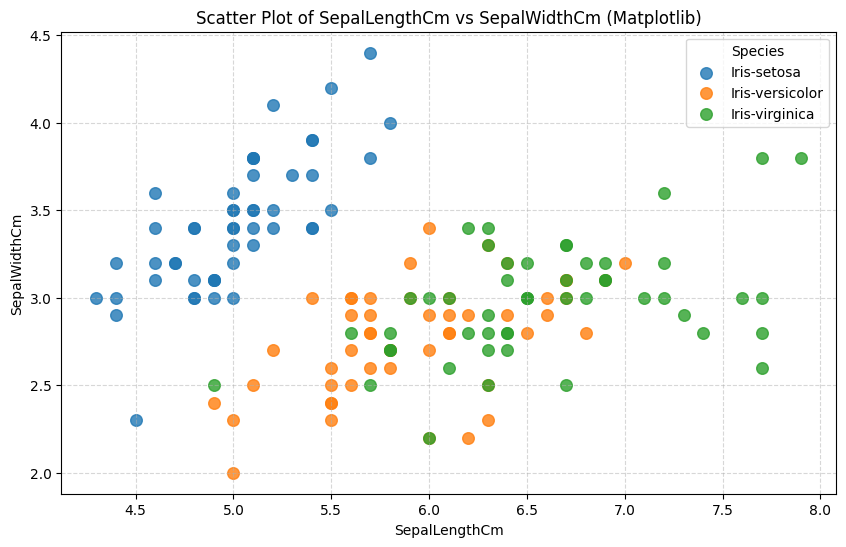

In [ ]:
# Define the missing column variables
species_col = 'Species'
sepal_x = 'SepalLengthCm'
sepal_y = 'SepalWidthCm'

# Create a scatter plot using only matplotlib
fig, ax = plt.subplots(figsize=(10, 6))

# Group by species and plot each group separately to handle colors and legend
for species, group in df.groupby(species_col):
    ax.scatter(group[sepal_x], group[sepal_y], label=species, s=70, alpha=0.8)

ax.set_title(f'Scatter Plot of {sepal_x} vs {sepal_y} (Matplotlib)')
ax.set_xlabel(sepal_x)
ax.set_ylabel(sepal_y)
ax.legend(title=species_col)
ax.grid(True, linestyle='--', alpha=0.5)
plt.show()

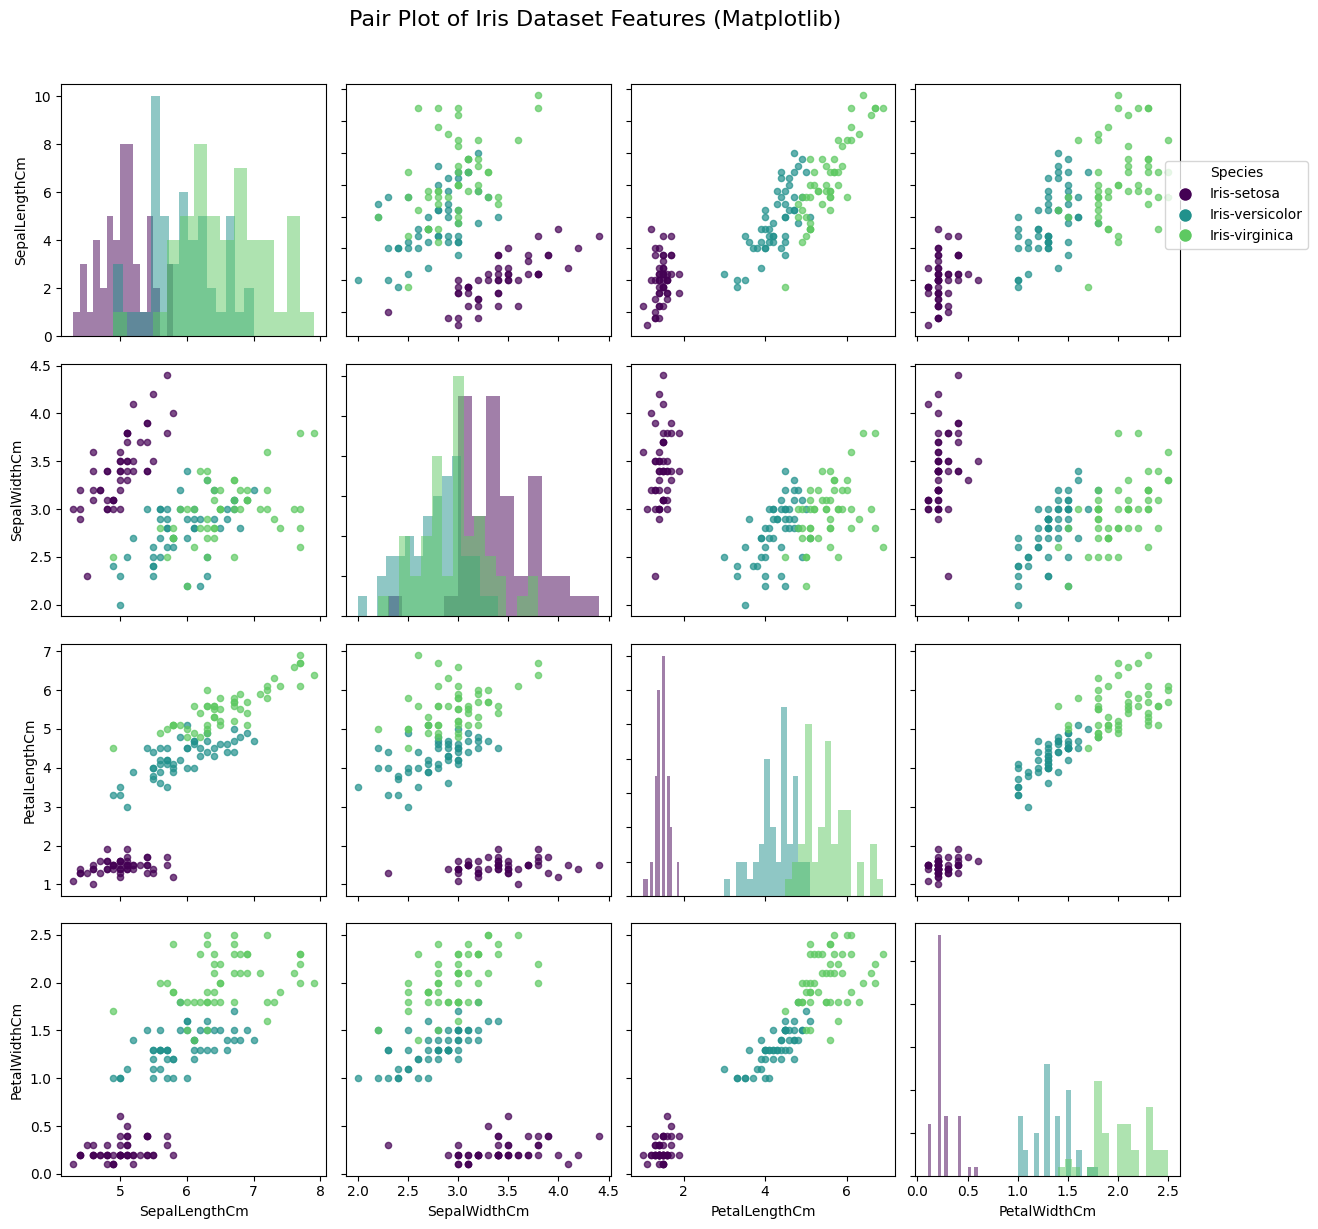

In [ ]:
# Create a pair plot manually using only matplotlib subplots
features = [col for col in numeric_cols if col != 'Id']
n_features = len(features)
fig, axs = plt.subplots(n_features, n_features, figsize=(12, 12))

# Get unique species for coloring
unique_species = df[species_col].unique()
colors = ['#440154', '#21918c', '#5ec962']  # Custom color palette matching viridis
species_colors = dict(zip(unique_species, colors))

for i in range(n_features):
    for j in range(n_features):
        ax = axs[i, j]
        feat_x = features[j]
        feat_y = features[i]

        if i == j:
            # Diagonal: Plot histograms for each species
            for species in unique_species:
                subset = df[df[species_col] == species]
                ax.hist(subset[feat_x], bins=15, alpha=0.5, label=species, color=species_colors[species])
        else:
            # Off-diagonal: Plot scatter plots
            for species in unique_species:
                subset = df[df[species_col] == species]
                ax.scatter(subset[feat_x], subset[feat_y], alpha=0.7, s=20, color=species_colors[species])

        # Formatting axes labels
        if i == n_features - 1:
            ax.set_xlabel(feat_x)
        else:
            ax.set_xticklabels([])

        if j == 0:
            ax.set_ylabel(feat_y)
        else:
            ax.set_yticklabels([])

# Add legend on top
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=colors[k], markersize=10, label=unique_species[k]) for k in range(len(unique_species))]
fig.legend(handles=handles, title=species_col, loc='upper right', bbox_to_anchor=(1.1, 0.9))

plt.suptitle('Pair Plot of Iris Dataset Features (Matplotlib)', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()